# Randomized quantum spectroscopy (RQS): experiment walkthrough

This notebook takes you from a list of signal frequencies to estimates of the signal's
Fourier amplitudes:

1. **Design** (steps 1–3): describe the signal and hardware, generate random pulse
   sequences, and plan which sequences to run.
2. **Run** (step 4): export the plan for your hardware and record the outcomes.
3. **Decode** (steps 6–7): load the outcomes and estimate the amplitudes and any linear
   observables of them.

You can run everything without hardware: step 5 simulates the measurement, and step 8
checks the accuracy against the known simulated signal. For real data, set
`USE_SIMULATED_DATA = False` in step 5 and point step 7 at your measured file.

**How to use it.** Run the cells top to bottom. Cells starting with **✏️** contain
settings to change; leave the others as they are. Units are Hz and seconds throughout.
Requires Python 3.10 or newer.

**Signal model.** The field at the sensor is
$b(t)=\sum_j \left[a_j\cos(2\pi f_j t)+b_j\sin(2\pi f_j t)\right]$, and it couples to the
qubit as $H = 2\pi\,\mathtt{coupling\_hz}\; b(t)\, Z/2$. The code estimates the amplitude
vector $A=(a_1,\dots,a_N,\,b_1,\dots,b_N)$: all cosine amplitudes, then all sine
amplitudes. An amplitude of 1 is the field $B_0$ for which
$2\pi\,\mathtt{coupling\_hz} = \gamma B_0$ ($\gamma$ is the sensor's gyromagnetic ratio).

In [4]:
# Setup: no edits needed.
import sys
if sys.version_info < (3, 10):
    raise RuntimeError(f"This notebook needs Python 3.10 or newer; this kernel runs "
                       f"{sys.version.split()[0]}. Select a newer Python kernel.")
from pathlib import Path
import importlib
import numpy as np
import matplotlib.pyplot as plt

# Import the package from this folder's src/ (no installation needed).
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/randomized_sensing").is_dir())
sys.path.insert(0, str(ROOT / "src"))
for name in tuple(sys.modules):  # re-import after any edits to the package
    if name.split(".")[0] == "randomized_sensing":
        del sys.modules[name]
importlib.invalidate_caches()

import randomized_sensing as R

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Describe the signal and hardware ✏️

| Setting | Meaning |
|---|---|
| `frequencies_hz` | **Every** frequency that may be present, including ones you don't care about: unlisted tones leak into the estimates. Distinct and positive (no DC); they need not be evenly spaced. |
| `coupling_hz` | Qubit phase rate for a unit-amplitude field, divided by $2\pi$. Sets the amplitude unit. |
| `t2_s` | Coherence time under these pulse sequences: contrast decays as $e^{-\tau/T_2}$. `None` means no decay. |
| `amplitude_bound` | Largest total signal size $\lVert A\rVert$ you expect. |
| `min_gap_s`, `edge_guard_s` | Shortest allowed time between two π pulses, and between a pulse and the start or end of a shot. |
| `clock_s` | Hardware timing resolution: every pulse time is a multiple of it. |
| `visibility`, `readout_bias` | Readout contrast without dephasing (1 = perfect), and the calibrated offset of the raw ±1 readout mean (usually 0). |
| `overhead_s` | Time per shot spent outside sensing (preparation, readout, reset). Only used for time estimates. |

`t2_s` and `visibility` set the contrast in simulations and a few safeguards; the
estimators do not need them to be exact.

**Acquisition mode** (`FIELD_MODE`):
- `"phase_locked"`: every shot starts at the same phase of the signal, because the
  signal restarts with each shot or the shots are triggered in sync with it. Repeated
  shots of the same sequence can be averaged.
- `"free_running"`: the signal runs continuously, so each shot starts at a different
  phase. You must record each shot's actual start time on one stable clock.
  `SHOT_PERIOD_S` is the planned time between shot starts (sensing plus overhead); the
  decoder uses the start times you actually record.

In [21]:
# ✏️ Your signal and hardware.
# Electron gyromagnetic ratio, in Hz/T
gamma_e_hz_per_t = 28e9

# Reference AC field along NV axis, in tesla
B_ref_t = 100e-9     

coupling_hz = gamma_e_hz_per_t * B_ref_t


experiment = R.Experiment(
    frequencies_hz=(60e3, 80e3, 100e3, 120e3, 140e3),  # every tone that may be present (20 kHz grid)
    coupling_hz=coupling_hz,# phase rate for a unit-amplitude field, / 2pi
    t2_s=100e-6,            # coherence time under the pulses (None = no decay)
    amplitude_bound=1.0,    # largest expected ||A|| (cosine and sine amplitudes together)
    min_gap_s=160e-9,       # 88 ns pi pulse + 20 ns gap
    edge_guard_s=64e-9,     # 44 ns half-pulse + 20 ns gap (the pool applies max(min_gap, edge_guard) = 108 ns)
    clock_s=4e-9,           # hardware timing resolution
    visibility=1.0,         # provisional: calibrate
    readout_bias=0.0,       # provisional: calibrate
    overhead_s=50e-3,       # time per shot outside sensing initialization +SCC readout (time estimates only)
)

FIELD_MODE = "phase_locked"   # "phase_locked" or "free_running"
SHOT_PERIOD_S = None          # free-running only: planned time between shot starts (None = sensing + overhead;


## 2. Build the random pulse sequences ✏️

The code generates a *pool* of random pulse sequences. Each one is the sign pattern of a
random sum of the signal's tones: the qubit's sensing sign flips (a π pulse) wherever
that sum changes sign, subject to the timing limits above. For each sequence it computes
exactly how strongly every Fourier component of the signal imprints on the qubit's phase
(the sequence's *response vector*). A negated copy of each sequence is added at no extra
hardware cost.

| Setting | Meaning |
|---|---|
| `duration_s` | Sensing time per shot, τ. It must be a whole number of clock cycles, and at least about 1/(smallest spacing between tones) so the tones can be told apart. |
| `max_pulses` | Optional cap on π pulses per sequence (`None` = no cap). Keep it loose: a tight cap changes the pool's statistics. |
| `start_time_s` | When each shot starts relative to the signal's $t = 0$, the phase reference for the amplitudes. Usually 0. |
| `seed` | Random seed; the same seed gives the same pool. |

**Choosing `duration_s`.** Longer shots pick up more signal per shot but lose contrast to
$T_2$, and a shot that is too long for a strong signal makes the phase wrap around. A
rough starting point is $\tau \approx 1.5\sqrt{N}/(2\pi\cdot\mathtt{coupling\_hz}\cdot\lVert A\rVert_{\max})$,
shortened if it is comparable to $T_2$. Then compare a few values in step 8 at equal
total sensing time.

**Check:** the condition number should be small (below 20). Larger values mean some
tones are hard to tell apart: the build warns above 20 and stops above 1000. Lengthen
`duration_s` or remove tones that are very close together.

In [22]:
# ✏️ Shot length and pool options.
pool = R.build_pool(
    experiment,
    duration_s=100e-6,    # sensing time per shot
    max_pulses=None,     # optional cap on pi pulses per sequence
    start_time_s=0.0,    # shot start relative to the signal's t = 0
    seed=4,
)

pulse_counts = [len(s.switch_times_s) for s in pool.sequences]
shortest = min(np.diff(np.r_[0., s.switch_times_s, pool.duration_s]).min() for s in pool.sequences)
print(f"Random sequences: {len(pool.sequences):,} (plus negated copies: {len(pool.Z):,} in the pool)")
print(f"Pi pulses per sequence: up to {max(pulse_counts)}; shortest interval {shortest*1e9:.1f} ns")
print(f"Condition number: {pool.condition:.2f}  (healthy below 20)")

Random sequences: 4,096 (plus negated copies: 8,192 in the pool)
Pi pulses per sequence: up to 28; shortest interval 160.0 ns
Condition number: 1.15  (healthy below 20)


One sequence from the pool, as an illustration. Top: the qubit's sensing sign over the
shot, flipping at each π pulse. Bottom: its response vector, i.e. how strongly each
cosine and sine component of the signal adds to the phase this sequence accumulates.

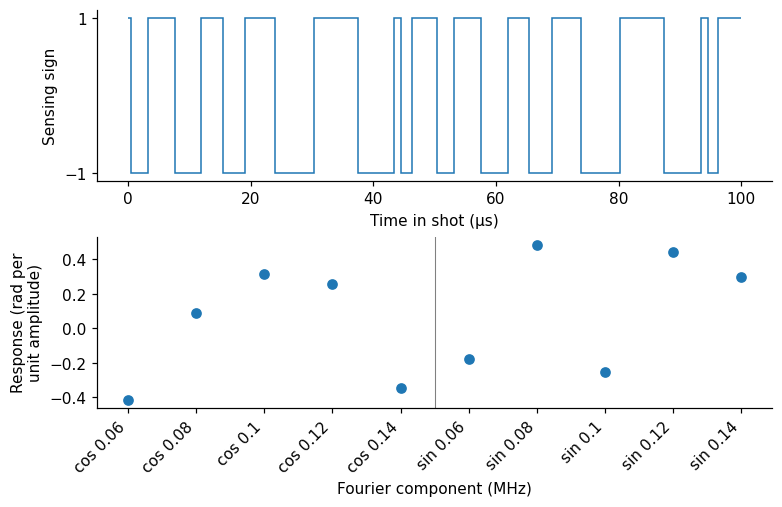

In [23]:
example = pool.sequence(1)
edges = np.r_[0., example.switch_times_s, pool.duration_s]
fig, (top, bottom) = plt.subplots(2, 1, figsize=(7, 4.5), constrained_layout=True)
top.stairs((-1.)**np.arange(len(edges)-1), edges*1e6, baseline=None)
top.set(xlabel="Time in shot (µs)", ylabel="Sensing sign", yticks=[-1, 1])
bottom.plot(np.arange(2*pool.N), pool.Z[1], "o")
bottom.axvline(pool.N-.5, color="grey", lw=.7)
bottom.set(ylabel="Response (rad per\nunit amplitude)")
if pool.N <= 12:
    f_mhz = np.asarray(experiment.frequencies_hz)/1e6
    bottom.set_xticks(np.arange(2*pool.N), [f"cos {f:g}" for f in f_mhz] + [f"sin {f:g}" for f in f_mhz],
                      rotation=45, ha="right")
    bottom.set_xlabel("Fourier component (MHz)")
else:
    bottom.set_xlabel("Fourier component: cosines, then sines")
plt.show()

## 3. Plan the acquisition ✏️

| Setting | Meaning |
|---|---|
| `n_shots` | Total number of shots (X and Y readout together). Error falls roughly as $1/\sqrt{n_\text{shots}}$; step 8 shows the resulting accuracy. |
| `x_fraction` | Fraction of shots read out in X; the rest are read out in Y. Y shots carry the signal; X shots measure how much the contrast is reduced. 0.1–0.3 is typical. |
| `seed` | Random seed for which sequences are drawn. |

Sequences are drawn from the pool at random, with repeats. In phase-locked mode, repeated
draws of the same sequence and readout basis are grouped into one row of the plan, so you
can run them back to back and average them. In free-running mode each row is one shot,
with a planned start time.

In [24]:
# ✏️ Shot budget.
plan = R.plan_acquisition(
    pool, n_shots=2_500, x_fraction=0.1, seed=5, field_mode=FIELD_MODE,
    **({"shot_period_s": SHOT_PERIOD_S} if FIELD_MODE == "free_running" else {}),
)

print(f"Mode: {plan.field_mode}; {plan.total_shots:,} shots in {len(plan.rows):,} rows")
print(f"Contrast per shot (visibility x T2 decay): {experiment.contrast(pool.duration_s):.3f}")
print(f"Sensing time: {plan.active_time_s*1e3:.1f} ms "
      f"({plan.time_with_overhead_s*1e3:.1f} ms including per-shot overhead)")

Mode: phase_locked; 2,500 shots in 2,205 rows
Contrast per shot (visibility x T2 decay): 0.368
Sensing time: 250.0 ms (125250.0 ms including per-shot overhead)


## 4. Export the files for the hardware ✏️

| File | Contents |
|---|---|
| `RUN.txt` | **Read this first:** the exact pulse and readout conventions. |
| `pulses.csv`, `intervals.csv` | The π-pulse times of each sequence, and the same sequences as ± intervals. |
| `acquisition.csv` | The plan: which sequence, which readout basis (X or Y), and how many shots, row by row. |
| `averages_template.csv` | Phase-locked: copy it and fill in the mean raw outcome (between −1 and +1) of each row. |
| `counts_template.csv` | Alternatively, the number of +1 outcomes of each row; in free-running mode, also each shot's measured start time. |
| `bundle.json`, `pool.npz`, `manifest.json`, `sequences.csv` | Everything the decoder needs, with integrity checks. Do not edit. |

**Running the experiment:**
- For each row: prepare $|{+}X\rangle$, play that sequence's π pulses (every sequence
  starts in the same frame; add no extra pulses), and read out in the row's basis.
- Record **raw** outcomes. Do not flip signs or subtract the readout offset: the decoder
  does both.
- Phase-locked: start every shot at the same signal phase. Free-running: record each
  shot's actual start time, in seconds from one stable clock and precise compared with
  1/(highest frequency); never average shots taken at different times.
- ⚠️ Re-running this cell overwrites the folder. Keep a copy of the folder you used on
  the hardware, and save your measured data under a new file name.

In [25]:
# ✏️ Folder for the exported files.
BUNDLE_DIR = ROOT / "outputs" / f"rqs_{FIELD_MODE}"

R.export_bundle(plan, BUNDLE_DIR, overwrite=True)
for file in sorted(BUNDLE_DIR.iterdir()):
    print(file.relative_to(ROOT))

outputs\rqs_phase_locked\acquisition.csv
outputs\rqs_phase_locked\averages_template.csv
outputs\rqs_phase_locked\bundle.json
outputs\rqs_phase_locked\counts_template.csv
outputs\rqs_phase_locked\intervals.csv
outputs\rqs_phase_locked\manifest.json
outputs\rqs_phase_locked\pool.npz
outputs\rqs_phase_locked\pulses.csv
outputs\rqs_phase_locked\RUN.txt
outputs\rqs_phase_locked\sequences.csv
outputs\rqs_phase_locked\simulated_averages.csv
outputs\rqs_phase_locked\simulated_counts.csv


This cell converts the exported sequences into OPX timing files: the full microwave sequence (preparation π/2, refocusing π pulses, analysis π/2) and an OPX-ready acquisition plan, using the π and π/2 durations and the 4 ns OPX clock.

In [26]:

from rqs_opx_export_with_pi2 import convert_rqs_bundle_to_opx

files = convert_rqs_bundle_to_opx(
    BUNDLE_DIR,
    pi_duration_ns=96,
    pi2_duration_ns=48,
    clock_ns=4,
)

print(files["full_microwave_csv"])


C:\Users\matth\GitHub\dioptric\RQS_toolkit\RQS_toolkit\outputs\rqs_phase_locked_opx_timing\opx_full_microwave_sequence.csv


In [28]:
import pandas as pd

# Folder containing the converted OPX files
opx_folder = BUNDLE_DIR.parent / (
    BUNDLE_DIR.name + "_opx_timing"
)

# Complete microwave sequence:
# preparation pi/2, refocusing pi pulses, analysis pi/2
microwave = pd.read_csv(
    opx_folder / "opx_full_microwave_sequence.csv"
)

# RQS acquisition plan
acquisition = pd.read_csv(
    opx_folder / "opx_ready_acquisition.csv"
)

print("Microwave sequence columns:")
print(microwave.columns.tolist())

print("\nAcquisition columns:")
print(acquisition.columns.tolist())

# Show the complete microwave sequence for the first acquisition row
first_row_id = acquisition.iloc[0]["row_id"]

example = microwave[
    microwave["row_id"] == first_row_id
].sort_values("gate_index")

print("\nComplete microwave sequence:")
display(example)

print("\nFirst 5 acquisition rows:")
display(acquisition.head(5))

Microwave sequence columns:
['row_id', 'sequence_index', 'measurement_basis', 'shots', 'gate_index', 'operation', 'pulse_type', 'nominal_rotation_axis', 'start_ns_from_first_pi2_start', 'duration_ns', 'end_ns_from_first_pi2_start', 'wait_before_ns', 'wait_before_cc']

Acquisition columns:
['plan_id', 'row_id', 'sequence_index', 'basis', 'shots', 'outcome_sign_DECODER_ONLY', 'sensing_duration_ns', 'pi_duration_ns', 'pi2_duration_ns', 'pulse_count', 'pi_centers_ns_from_sensing_start', 'pi_starts_ns_from_first_pi2', 'waits_ns', 'waits_cc', 'final_pi2_start_ns_from_first_pi2', 'full_mw_duration_ns']

Complete microwave sequence:


,row_id,sequence_index,measurement_basis,shots,gate_index,operation,pulse_type,nominal_rotation_axis,start_ns_from_first_pi2_start,duration_ns,end_ns_from_first_pi2_start,wait_before_ns,wait_before_cc
0,Y_0,0,Y,1,0,PREPARE_PLUS_X,PI_OVER_2,+Y,0,48,48,0,0
1,Y_0,0,Y,1,1,REFOCUS,PI,+X,3712,96,3808,3664,916
2,Y_0,0,Y,1,2,REFOCUS,PI,+X,7192,96,7288,3384,846
3,Y_0,0,Y,1,3,REFOCUS,PI,+X,10380,96,10476,3092,773
4,Y_0,0,Y,1,4,REFOCUS,PI,+X,15100,96,15196,4624,1156
5,Y_0,0,Y,1,5,REFOCUS,PI,+X,20600,96,20696,5404,1351
6,Y_0,0,Y,1,6,REFOCUS,PI,+X,29272,96,29368,8576,2144
7,Y_0,0,Y,1,7,REFOCUS,PI,+X,34120,96,34216,4752,1188
8,Y_0,0,Y,1,8,REFOCUS,PI,+X,38260,96,38356,4044,1011
9,Y_0,0,Y,1,9,REFOCUS,PI,+X,41880,96,41976,3524,881



First 5 acquisition rows:


,plan_id,row_id,sequence_index,basis,shots,outcome_sign_DECODER_ONLY,sensing_duration_ns,pi_duration_ns,pi2_duration_ns,pulse_count,pi_centers_ns_from_sensing_start,pi_starts_ns_from_first_pi2,waits_ns,waits_cc,final_pi2_start_ns_from_first_pi2,full_mw_duration_ns
0,619263120b2b5f2d264f780d13c9f26150e51320df0ff7...,Y_0,0,Y,1,1,100000,96,48,20,3712;7192;10380;15100;20600;29272;34120;38260;...,3712;7192;10380;15100;20600;29272;34120;38260;...,3664;3384;3092;4624;5404;8576;4752;4044;3524;5...,916;846;773;1156;1351;2144;1188;1011;881;1453;...,100048,100096
1,619263120b2b5f2d264f780d13c9f26150e51320df0ff7...,Y_7,7,Y,1,-1,100000,96,48,20,2088;6824;11520;15000;17880;22620;29488;36172;...,2088;6824;11520;15000;17880;22620;29488;36172;...,2040;4640;4600;3384;2784;4644;6772;6588;5264;6...,510;1160;1150;846;696;1161;1693;1647;1316;1548...,100048,100096
2,619263120b2b5f2d264f780d13c9f26150e51320df0ff7...,Y_8,8,Y,1,-1,100000,96,48,24,2256;7112;11848;12472;16864;21304;25168;29848;...,2256;7112;11848;12472;16864;21304;25168;29848;...,2208;4760;4640;528;4296;4344;3768;4584;6280;52...,552;1190;1160;132;1074;1086;942;1146;1570;1324...,100048,100096
3,619263120b2b5f2d264f780d13c9f26150e51320df0ff7...,Y_9,9,Y,2,1,100000,96,48,24,1728;8152;13076;17040;20684;24748;27296;30552;...,1728;8152;13076;17040;20684;24748;27296;30552;...,1680;6328;4828;3868;3548;3968;2452;3160;4652;4...,420;1582;1207;967;887;992;613;790;1163;1222;45...,100048,100096
4,619263120b2b5f2d264f780d13c9f26150e51320df0ff7...,Y_12,12,Y,1,-1,100000,96,48,20,2904;6060;9688;14336;19496;29696;37364;42428;4...,2904;6060;9688;14336;19496;29696;37364;42428;4...,2856;3060;3532;4552;5064;10104;7572;4968;4184;...,714;765;883;1138;1266;2526;1893;1242;1046;691;...,100048,100096


## 5. Simulated data (skip on hardware) ✏️

While `USE_SIMULATED_DATA = True`, this cell makes a test signal, simulates the planned
measurement (same pulses, contrast and readout model), and saves the outcomes in the same
format as the hardware templates. Choose the test signal with `TEST_SIGNAL`:

- `"single_tone"`: one tone at `TRUE_F_HZ`, which must be one of `frequencies_hz`, with
  cosine and sine amplitudes `TRUE_P` and `TRUE_Q` in units of `B_ref_t`.
- `"random"`: random amplitudes on every tone, with total size `SIGNAL_NORM`.

In both cases the decoder sees only the candidate frequencies and the simulated outcomes;
`true_amplitudes` is used only to score the results in step 8. Set
`USE_SIMULATED_DATA = False` once you have measured data: this is the only place it is set.

In [29]:
# ✏️ Simulation settings.
USE_SIMULATED_DATA = True     # set False once you have measured data
TEST_SIGNAL = "single_tone"   # "single_tone" or "random"

TRUE_F_HZ = 100e3              # "single_tone": must be one of frequencies_hz
TRUE_P, TRUE_Q = 0.4, 0.3     # "single_tone": cosine and sine amplitudes, in units of B_ref_t
SIGNAL_NORM = 0.5             # "random": ||A|| of the random test signal

if USE_SIMULATED_DATA:
    rng = np.random.default_rng(4)
    N = pool.N
    if TEST_SIGNAL == "single_tone":
        match = np.flatnonzero(np.isclose(experiment.frequencies_hz, TRUE_F_HZ))
        if not match.size:
            raise ValueError("TRUE_F_HZ must be one of frequencies_hz: the simulator only knows the listed tones.")
        true_amplitudes = np.zeros(2*N)
        true_amplitudes[match[0]], true_amplitudes[N + match[0]] = TRUE_P, TRUE_Q
    elif TEST_SIGNAL == "random":
        true_amplitudes = rng.normal(size=2*N)
        true_amplitudes *= SIGNAL_NORM/np.linalg.norm(true_amplitudes)
    else:
        raise ValueError(f"Unknown TEST_SIGNAL {TEST_SIGNAL!r}")

    sim_start_times = None
    if FIELD_MODE == "free_running":  # recorded starts = planned starts + small trigger delays
        planned_starts = np.array([row["start_time_s"] for row in plan.rows])
        sim_start_times = planned_starts + rng.uniform(0, 10e-9, len(planned_starts))

    sim_counts = R.simulate(plan, true_amplitudes, seed=42, start_times_s=sim_start_times)
    R.write_counts(BUNDLE_DIR / "simulated_counts.csv", plan, sim_counts)
    if FIELD_MODE == "phase_locked":
        sim_means = [2*sim_counts[row["row_id"]]/row["shots"] - 1 for row in plan.rows]
        R.write_averages(BUNDLE_DIR / "simulated_averages.csv", plan, sim_means)

    true_nT = B_ref_t*1e9*np.hypot(true_amplitudes[:N], true_amplitudes[N:])
    print(f"Test signal: {TEST_SIGNAL}")
    for f, b in zip(experiment.frequencies_hz, true_nT):
        print(f"  {f/1e3:6.1f} kHz: {b:6.2f} nT")
    print("Simulated outcomes saved in", BUNDLE_DIR.relative_to(ROOT))

Test signal: single_tone
    60.0 kHz:   0.00 nT
    80.0 kHz:   0.00 nT
   100.0 kHz:  50.00 nT
   120.0 kHz:   0.00 nT
   140.0 kHz:   0.00 nT
Simulated outcomes saved in outputs\rqs_phase_locked


## 6. Choose the observables ✏️

Each observable is a weighted sum of the amplitudes, $F=\sum_j (c_j a_j + s_j b_j)$.
Each row of `cosine_weights` and `sine_weights` defines one observable; the columns
follow the order of `frequencies_hz`. For example, the cosine amplitude of the second
tone alone is the cosine row `[0, 1, 0, 0]` with an all-zero sine row; the overlap with
a template waveform uses that waveform's Fourier coefficients as the weights.

The observables are computed from the decoded amplitudes, so you can change them after
taking data and rerun from here without measuring again.

In [30]:
# ✏️ One row per observable; columns follow the order of frequencies_hz.
N = pool.N

cosine_weights = np.vstack([
    np.eye(N),
    np.zeros((N, N)),
])

sine_weights = np.vstack([
    np.zeros((N, N)),
    np.eye(N),
])

observable_weights = dict(
    cosine_weights=cosine_weights,
    sine_weights=sine_weights,
)
print("Cosine weights shape:", cosine_weights.shape)
print("Sine weights shape:", sine_weights.shape)

Cosine weights shape: (10, 5)
Sine weights shape: (10, 5)


## 7. Load the data and decode ✏️

Choose how your measured data are provided (ignored while `USE_SIMULATED_DATA` is on):

| `DATA_FORMAT` | Mode | What to provide |
|---|---|---|
| `"averages_csv"` | phase-locked | `DATA_FILE`: your filled-in copy of `averages_template.csv` (mean raw outcome in [−1, 1] and number of repetitions per row) |
| `"counts_csv"` | either | `DATA_FILE`: your filled-in copy of `counts_template.csv` (number of +1 outcomes per row; free-running: also each shot's measured start time) |
| `"values"` | phase-locked | `mean_values`: one mean raw outcome per row of `acquisition.csv`, in order; optionally `repetitions` |
| `"timed_values"` | free-running | `raw_values` (one raw outcome in [−1, 1] per shot) and `measured_start_times` (seconds), in `acquisition.csv` order |

The plan is reloaded from `BUNDLE_DIR`, so decoding always uses exactly the files you ran
on the hardware. If you restart the notebook, run steps 1–6 again with the same settings
or set `BUNDLE_DIR` to that folder directly.

Set `N_NV` to the number of NVs. With `N_NV = 1` everything works as before. With `N_NV > 1`, each NV is decoded separately (with its own visibility, readout offset and T2), and the signed amplitudes are averaged, weighted by each NV's contrast squared; the error bars come from the scatter between NVs. Measured data then come as one file per NV (`measured_averages_nv0.csv`, `measured_averages_nv1.csv`, …), and simulated data as `N_NV` NVs with step 5's test signal and independent noise. Average only NVs with the same orientation.

Two estimators are run for comparison:
- **RQS**: fast, and works with any number of shots.
- **RQS-ML** (phase-locked) or **TIMESTAMPED-ML** (free-running): refines the RQS result
  by fitting the outcomes directly. It is often noticeably more accurate when there are
  few tones, but slower and less helpful with many tones. It needs at least $6N$ shots;
  with fewer it returns the RQS result and says why.

In [31]:
# Helper for N_NV > 1: no edits needed.
import copy, dataclasses
from scipy.linalg import cho_solve
from randomized_sensing._estimator import correct_tones

def decode_nvs(plan, n_nv, simulated, *, true_amplitudes=None, start_times_s=None, files=None,
               data_format="averages_csv", visibility=None, offset=None, t2_s=None,
               observable_weights=None, seed=42, verbose=True):
    """Combine n_nv NVs that were read out in the same shots.

    RQS: the NVs' data are pooled first (Y back-projections and X means, each NV weighted by its contrast),
    then decoded once, so no NV is divided by its own noisy X mean. The refined method is decoded per NV
    and averaged with weights contrast². Returns (estimates, details): estimates[method] has the same form
    as a single-NV result, so the later cells work unchanged; details[method] holds the standard errors
    (from the scatter between NVs), the magnitudes in nT and the amplitudes of each NV.
    """
    pool, experiment, n = plan.pool, plan.pool.experiment, plan.pool.N
    pooled = plan.field_mode == "phase_locked"
    methods = ("RQS", "RQS-ML" if pooled else "TIMESTAMPED-ML")
    if simulated and true_amplitudes is None:
        raise RuntimeError("Simulated NVs need step 5's true_amplitudes: run step 5 with USE_SIMULATED_DATA = True.")
    if not simulated and data_format not in ("averages_csv", "counts_csv"):
        raise ValueError("With N_NV > 1, use DATA_FORMAT 'averages_csv' or 'counts_csv' (one file per NV).")
    correct_tones(pool, np.zeros(2*n))           # build the per-tone correction table once; NV copies share it

    def per_nv_values(value, default):
        value = default if value is None else value
        return np.broadcast_to(np.asarray(np.nan if value is None else value, float), (n_nv,))
    vis, off, t2 = (per_nv_values(visibility, experiment.visibility),
                    per_nv_values(offset, experiment.readout_bias), per_nv_values(t2_s, experiment.t2_s))
    contrast = vis*np.exp(-pool.duration_s/np.where(np.isnan(t2), np.inf, t2))   # known, not from the data

    def plan_for_nv(i):                          # same pulses and rows, with this NV's readout and T2
        nv_pool = copy.copy(pool)
        nv_pool.experiment = dataclasses.replace(experiment, visibility=float(vis[i]), readout_bias=float(off[i]),
                                                 t2_s=None if np.isnan(t2[i]) else float(t2[i]))
        return dataclasses.replace(plan, pool=nv_pool)

    rows = plan.rows
    is_y = np.array([r["basis"] == "Y" for r in rows])
    shots = np.array([r["shots"] for r in rows], float)
    signed_Z = np.array([r["outcome_sign"]*pool.Z[r["sequence_index"]] for r in rows])
    per_nv, back, x_raw = {m: [] for m in methods}, [], []
    for i in range(n_nv):
        nv_plan = plan_for_nv(i)
        if simulated:
            timing = {} if pooled else {"start_times_s": start_times_s}
            data = R.simulate(nv_plan, true_amplitudes, seed=seed + i, **timing)
        elif data_format == "averages_csv":
            data = R.read_averages(files[i], plan)
        else:
            data = R.read_counts(files[i], plan)
        for m in methods:
            per_nv[m].append(R.decode(nv_plan, data, method=m))
        if pooled:                               # this NV's Y back-projection and X mean, offset removed
            means = (np.array([data.means[r["row_id"]] for r in rows]) if isinstance(data, R.AveragedOutcomes)
                     else np.array([2*data[r["row_id"]]/r["shots"] - 1 for r in rows]))
            raw = means - off[i]
            back.append((shots[is_y]*raw[is_y]) @ signed_Z[is_y]/shots[is_y].sum())
            x_raw.append(shots[~is_y] @ raw[~is_y]/shots[~is_y].sum())

    keep = np.array([e.x_mean for e in per_nv["RQS"]]) > 0
    if verbose and not keep.all():
        print("Left out (X mean not positive; check the X-analysis pulse):", np.flatnonzero(~keep).tolist())
    used = int(keep.sum())
    w = np.where(keep, contrast, 0.)             # weight of each NV's data
    w2 = w**2                                    # weight of each NV's estimate (its noise scales as 1/contrast)
    if pooled:
        v, mu = w @ np.array(back)/w.sum(), w @ np.array(x_raw)/w.sum()
        floor = (w @ contrast/w.sum())*np.exp(-pool.lam_max*experiment.amplitude_bound**2/2)
    to_nT = B_ref_t*1e9
    estimates, details = {}, {}
    for m in methods:
        A_nv = np.array([e.amplitudes for e in per_nv[m]])
        mean = w2 @ A_nv/w2.sum()
        se = (np.sqrt(w2 @ (A_nv - mean)**2/((used - 1)*w2.sum())) if used > 1 else np.full(2*n, np.nan))
        ok = [e for e, k in zip(per_nv[m], keep) if k]
        x_mean, guard = float(w2[keep] @ [e.x_mean for e in ok]/w2.sum()), float(ok[0].guard_floor)
        if pooled:
            x_mean, guard = float(mu), float(floor)
            if m == "RQS":                       # pool the data, then decode once
                mean = correct_tones(pool, cho_solve(pool.chol, v)/max(mu, floor))
        mag = np.hypot(mean[:n], mean[n:])
        mag_se = np.hypot(mean[:n]*se[:n], mean[n:]*se[n:])/np.maximum(mag, 1e-12)
        fitted = [e.fitted_contrast for e in ok if e.fitted_contrast is not None]
        values = R.evaluate_observables(mean, **observable_weights) if observable_weights else ()
        estimates[m] = dataclasses.replace(
            ok[0], amplitudes=tuple(np.asarray(mean).tolist()), values=tuple(values), x_mean=x_mean,
            guard_floor=guard, floor_active=x_mean < guard, ml_applied=all(e.ml_applied for e in ok),
            fitted_contrast=float(np.mean(fitted)) if fitted else None)
        details[m] = dict(se=se, magnitude_nT=to_nT*mag, magnitude_se_nT=to_nT*mag_se, per_nv=A_nv[keep])
        if verbose and used > 1:
            single = np.sqrt(w2 @ (A_nv - mean)**2/w2.sum())
            how = "pooled" if m == "RQS" and pooled else "averaged"
            line = (f"{m:15s} noise per component: single NV {to_nT*np.median(single):.1f} nT"
                    f" -> {how} over {used} NVs {to_nT*np.median(se):.1f} nT")
            if simulated:
                single_error = np.median(np.sqrt(np.mean((A_nv[keep] - true_amplitudes)**2, axis=1)))
                line += (f";  rms error vs truth {to_nT*single_error:.1f} ->"
                         f" {to_nT*np.sqrt(np.mean((mean - true_amplitudes)**2)):.1f} nT")
            print(line)
    return estimates, details

# Step 3 helper (phase cycling): no edits needed.
def combine_phase_cycled(plan, target):
    """Write `target` as the half-difference of `<target>_plus.csv` and `<target>_minus.csv`.

    _plus:  the rows measured with the normal analysis π/2.
    _minus: the same rows with the analysis π/2 shifted by 180°.
    (m+ - m-)/2 keeps the signal and cancels the readout offset; (m+ + m-)/2 is the offset itself.
    """
    target = Path(target)
    plus, minus = (R.read_averages(target.with_name(f"{target.stem}_{s}.csv"), plan) for s in ("plus", "minus"))
    ids = [r["row_id"] for r in plan.rows]
    shots = np.array([r["shots"] for r in plan.rows], float)
    means = [(plus.means[i] - minus.means[i])/2 for i in ids]
    reps = [plus.repetitions[i] + minus.repetitions[i] for i in ids]
    offset = shots @ [(plus.means[i] + minus.means[i])/2 for i in ids]/shots.sum()
    R.write_averages(target, plan, means, repetitions=reps)
    print(f"{target.name}: half-difference of the two analysis phases (readout offset removed: {offset:+.4f})")

In [32]:
# ✏️ Your measured data (ignored while USE_SIMULATED_DATA is True).
N_NV = 100                       # 1 = one NV; >1 = NVs with the same orientation, decoded separately and averaged
DATA_FORMAT = "averages_csv"   # "averages_csv", "counts_csv", "values" or "timed_values" (N_NV > 1: a "_csv" format)
DATA_FILE = BUNDLE_DIR / "measured_averages.csv"                                             # N_NV = 1
NV_DATA_FILES = [BUNDLE_DIR / f"measured_{DATA_FORMAT.split('_')[0]}_nv{i}.csv" for i in range(N_NV)]  # N_NV > 1
NV_VISIBILITY = NV_OFFSET = NV_T2 = None   # N_NV > 1: one value per NV (e.g. cal_visibility), or None = bundle value
PHASE_CYCLED = False           # True: combine the *_plus.csv and *_minus.csv files of each data file first (step 3)
mean_values, repetitions = None, None            # for "values"
raw_values, measured_start_times = None, None    # for "timed_values"

if USE_SIMULATED_DATA:
    DATA_FORMAT = "averages_csv" if FIELD_MODE == "phase_locked" else "counts_csv"
    DATA_FILE = BUNDLE_DIR / f"simulated_{DATA_FORMAT.split('_')[0]}.csv"

saved_plan = R.load_bundle(BUNDLE_DIR)
refined = "TIMESTAMPED-ML" if saved_plan.field_mode == "free_running" else "RQS-ML"
if PHASE_CYCLED and not USE_SIMULATED_DATA:   # the readout offset cancels in the half-difference
    if DATA_FORMAT != "averages_csv" or saved_plan.field_mode != "phase_locked":
        raise ValueError("Phase cycling here needs phase-locked data in averages files.")
    if saved_plan.pool.experiment.readout_bias != 0 or NV_OFFSET is not None:
        raise ValueError("With phase cycling the offset is already removed: set readout_bias = 0 and NV_OFFSET = None.")
    for target in ([DATA_FILE] if N_NV == 1 else NV_DATA_FILES):
        combine_phase_cycled(saved_plan, target)
if N_NV > 1:   # simulated: N_NV NVs with step 5's signal and independent noise; measured: NV_DATA_FILES
    results, nv_details = decode_nvs(
        saved_plan, N_NV, USE_SIMULATED_DATA, true_amplitudes=globals().get("true_amplitudes"),
        start_times_s=globals().get("sim_start_times"), files=NV_DATA_FILES, data_format=DATA_FORMAT,
        visibility=NV_VISIBILITY, offset=NV_OFFSET, t2_s=NV_T2, observable_weights=observable_weights)
else:
    if DATA_FORMAT == "averages_csv":
        data = R.read_averages(DATA_FILE, saved_plan)
    elif DATA_FORMAT == "counts_csv":
        data = R.read_counts(DATA_FILE, saved_plan)
    elif DATA_FORMAT == "values":
        data = R.AveragedOutcomes(mean_values, repetitions)
    elif DATA_FORMAT == "timed_values":
        data = R.TimedOutcomes(raw_values, measured_start_times)
    else:
        raise ValueError(f"Unknown DATA_FORMAT {DATA_FORMAT!r}")
    results = {method: R.decode(saved_plan, data, method=method, **observable_weights)
               for method in ("RQS", refined)}


RQS             noise per component: single NV 16.5 nT -> pooled over 100 NVs 1.7 nT;  rms error vs truth 16.2 -> 1.9 nT
RQS-ML          noise per component: single NV 18.0 nT -> averaged over 100 NVs 1.8 nT;  rms error vs truth 17.4 -> 1.8 nT


**Reading the results.** For each estimator: the observables, then the decoded amplitude
of every tone. The last line is a health check:
- *X mean* is the average X-readout outcome. If *floor active* is `True`, it is too
  small for a reliable estimate: the shots are too long for this signal, or the signal is
  stronger than expected.
- *Fitted contrast* (refined estimator only) should be close to the contrast per shot
  printed in step 3.

In [33]:
N = saved_plan.pool.N
tones_mhz = np.asarray(saved_plan.pool.experiment.frequencies_hz)/1e6
if N_NV > 1:
    print(f"Average over {N_NV} NVs; (± ...) = standard errors of the cos and sin amplitudes\n")
for method, result in results.items():
    skipped = "" if method == "RQS" or result.ml_applied else f"  (refinement skipped: {result.refinement_skipped_reason})"
    print(f"{method}{skipped}")
    for j, value in enumerate(result.values, start=1):
        print(f"  F{j} = {value:+.5f}")
    amplitudes = np.asarray(result.amplitudes)
    se = nv_details[method]["se"] if N_NV > 1 else None
    if N <= 20:
        print("  tone (MHz)    cos amp    sin amp  magnitude")
        for j, (f, a, b) in enumerate(zip(tones_mhz, amplitudes[:N], amplitudes[N:])):
            errors = "" if se is None else f"   (± {se[j]:.4f}, ± {se[N+j]:.4f})"
            print(f"  {f:10.4g}  {a:+9.4f}  {b:+9.4f}  {np.hypot(a, b):9.4f}{errors}")
    else:
        print(f"  {2*N} amplitudes in results[{method!r}].amplitudes (cosines, then sines)")
    contrast = "" if result.fitted_contrast is None else f"; fitted contrast {result.fitted_contrast:.3f}"
    print(f"  X mean {result.x_mean:.3f} (floor {result.guard_floor:.3f}, floor active: {result.floor_active}){contrast}\n")


Average over 100 NVs; (± ...) = standard errors of the cos and sin amplitudes

RQS
  F1 = -0.00629
  F2 = -0.02399
  F3 = +0.36629
  F4 = +0.01175
  F5 = +0.01987
  F6 = +0.00212
  F7 = -0.01288
  F8 = +0.33123
  F9 = -0.01022
  F10 = -0.00885
  tone (MHz)    cos amp    sin amp  magnitude
        0.06    -0.0063    +0.0021     0.0066   (± 0.0154, ± 0.0163)
        0.08    -0.0240    -0.0129     0.0272   (± 0.0176, ± 0.0171)
         0.1    +0.3663    +0.3312     0.4938   (± 0.0160, ± 0.0166)
        0.12    +0.0117    -0.0102     0.0156   (± 0.0177, ± 0.0166)
        0.14    +0.0199    -0.0089     0.0218   (± 0.0164, ± 0.0179)
  X mean 0.363 (floor 0.346, floor active: False)

RQS-ML
  F1 = +0.00525
  F2 = -0.01179
  F3 = +0.39802
  F4 = -0.00541
  F5 = +0.01608
  F6 = -0.00881
  F7 = -0.01804
  F8 = +0.34726
  F9 = +0.00301
  F10 = -0.00138
  tone (MHz)    cos amp    sin amp  magnitude
        0.06    +0.0053    -0.0088     0.0103   (± 0.0167, ± 0.0175)
        0.08    -0.0118    -0.0

**Reconstructed spectrum.** The field magnitude at each candidate frequency,
`B_ref_t` × √(cos amp² + sin amp²), for both estimators. With simulated data the true
magnitudes are overlaid. Magnitudes are never negative, so tones without signal still show
a noise-level bar; a tone that is not in `frequencies_hz` spreads over its neighbors.

**Average over NVs.** Every NV is read out in the same shots, so all NVs share one plan. Each NV
is decoded on its own, with its own visibility, readout offset and T2, and the signed cosine and
sine amplitudes are then averaged, weighted by each NV's contrast squared. Averaging the signed
amplitudes, not the magnitudes, is what makes the noise shrink as 1/√(number of NVs). The error
bars come from the scatter between NVs. Include only NVs with the same orientation, since each
NV senses the field's projection on its own axis.

## 8. Check the accuracy on simulated data

Because the simulated signal is known, the errors can be measured directly. These cells
need the simulated data from step 5 and are skipped otherwise.

1. **Observables:** the estimates next to the true values. The last column is RQS with
   unlimited shots: its difference from the truth is the estimator's own small bias,
   which more shots will not remove.
2. **All amplitudes:** every component of the decoded amplitude vector against the
   truth (top), and the error of each component (bottom).
3. **Repeated experiments:** the same plan simulated `N_TRIALS` times with fresh noise.
   This gives the typical and the near-worst-case error to expect for this signal and
   shot budget.

Use these checks to choose `duration_s`, `n_shots` and `x_fraction` before running on
hardware: try a few settings and compare the errors at the same total sensing time. The
numbers apply to the test signal in step 5, so make it resemble the signals you expect.

RQS             strongest tone: 100 kHz, 49.4 nT
RQS-ML          strongest tone: 100 kHz, 52.8 nT


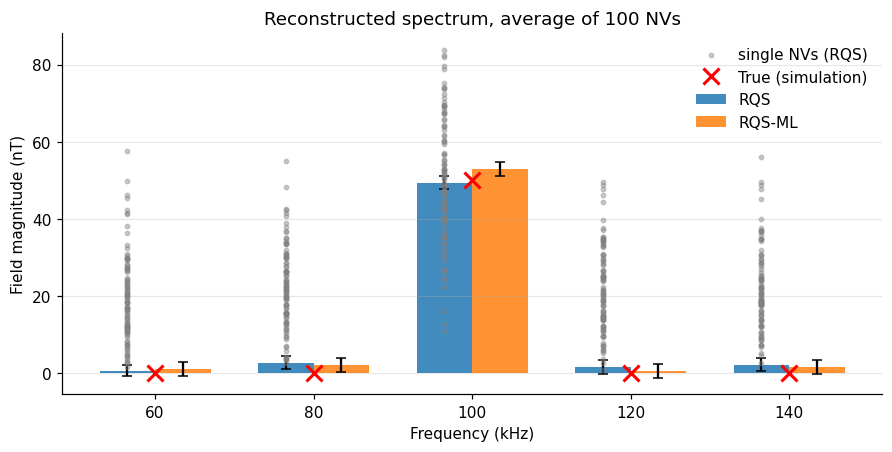

In [34]:
f_khz = np.asarray(saved_plan.pool.experiment.frequencies_hz)/1e3
N = saved_plan.pool.N
width = 0.35*np.min(np.diff(np.sort(f_khz))) if N > 1 else 1.0

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
for shift, (method, result) in zip((-width/2, width/2), results.items()):
    A_hat = np.asarray(result.amplitudes)
    magnitude_nT = B_ref_t*1e9*np.hypot(A_hat[:N], A_hat[N:])
    error_nT = nv_details[method]["magnitude_se_nT"] if N_NV > 1 else None
    ax.bar(f_khz + shift, magnitude_nT, width=width, yerr=error_nT, capsize=3, alpha=.85, label=method)
    k = int(np.argmax(magnitude_nT))
    print(f"{method:15s} strongest tone: {f_khz[k]:g} kHz, {magnitude_nT[k]:.1f} nT")
if N_NV > 1:
    singles = B_ref_t*1e9*np.hypot(nv_details["RQS"]["per_nv"][:, :N], nv_details["RQS"]["per_nv"][:, N:])
    ax.scatter(np.repeat(f_khz - width/2, len(singles)), singles.T.ravel(), s=8, color="grey", alpha=.4,
               label="single NVs (RQS)", zorder=3)
if USE_SIMULATED_DATA:
    true_nT = B_ref_t*1e9*np.hypot(true_amplitudes[:N], true_amplitudes[N:])
    ax.plot(f_khz, true_nT, "x", color="red", ms=10, mew=2, label="True (simulation)", zorder=4)
ax.set(xticks=f_khz, xlabel="Frequency (kHz)", ylabel="Field magnitude (nT)",
       title="Reconstructed spectrum" + (f", average of {N_NV} NVs" if N_NV > 1 else ""))
ax.legend(frameon=False)
ax.grid(alpha=.3, axis="y")
plt.show()


In [18]:
if not USE_SIMULATED_DATA:
    print("Skipped: needs the simulated data from step 5.")
else:
    truth = np.asarray(R.evaluate_observables(true_amplitudes, **observable_weights))
    timing = {"start_times_s": sim_start_times} if FIELD_MODE == "free_running" else {}
    noise_free = R.population_estimate(saved_plan, true_amplitudes, **observable_weights, **timing)
    print("           true  " + "".join(f"{m:>16s}" for m in results) + "   RQS, unlimited shots")
    for j, value in enumerate(truth):
        estimates = "".join(f"{results[m].values[j]:+16.5f}" for m in results)
        print(f"  F{j+1}  {value:+.5f}{estimates}   {noise_free.values[j]:+.5f}")

           true               RQS          RQS-ML   RQS, unlimited shots
  F1  +0.00000        -0.00190        -0.00394   +0.00008
  F2  +0.00000        +0.00116        +0.00393   +0.00001
  F3  +0.40000        +0.39026        +0.39738   +0.39999
  F4  +0.00000        -0.02132        -0.02065   +0.00001
  F5  +0.00000        -0.00421        -0.00503   +0.00009
  F6  +0.00000        +0.01536        +0.01392   -0.00014
  F7  +0.00000        -0.00112        +0.00276   +0.00004
  F8  +0.30000        +0.29342        +0.29522   +0.30001
  F9  +0.00000        -0.01659        -0.01092   +0.00002
  F10  +0.00000        -0.00290        +0.00136   +0.00002


RQS: largest amplitude error 0.0337; overall error 12.0% of ||A||
RQS-ML: largest amplitude error 0.0473; overall error 11.1% of ||A||


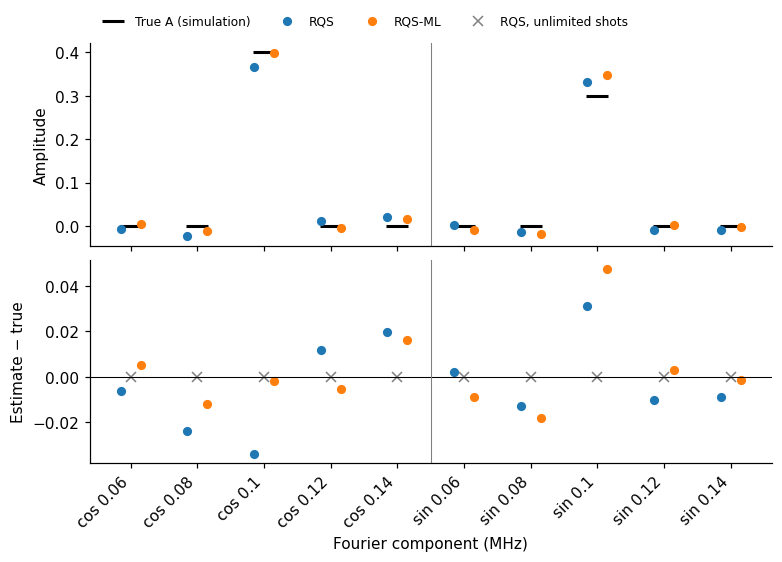

In [35]:
if USE_SIMULATED_DATA:
    x = np.arange(2*N)
    shift = np.linspace(-.15, .15, len(results))
    fig, (top, bottom) = plt.subplots(2, 1, figsize=(7, 5), sharex=True, constrained_layout=True)
    top.plot(x, true_amplitudes, "k_", ms=14, mew=2, label="True A (simulation)")
    for dx, (method, result) in zip(shift, results.items()):
        error = np.asarray(result.amplitudes) - true_amplitudes
        top.plot(x+dx, result.amplitudes, "o", ms=5, label=method)
        bottom.plot(x+dx, error, "o", ms=5)
        print(f"{method}: largest amplitude error {np.max(np.abs(error)):.4f}; "
              f"overall error {np.linalg.norm(error)/np.linalg.norm(true_amplitudes):.1%} of ||A||")
    bottom.plot(x, np.asarray(noise_free.amplitudes) - true_amplitudes, "x", color="grey",
                label="RQS, unlimited shots")
    bottom.axhline(0, color="k", lw=.7)
    for ax in (top, bottom):
        ax.axvline(N-.5, color="grey", lw=.7)
    top.set(ylabel="Amplitude")
    bottom.set(ylabel="Estimate − true")
    if N <= 12:
        bottom.set_xticks(x, [f"cos {f:g}" for f in tones_mhz] + [f"sin {f:g}" for f in tones_mhz],
                          rotation=45, ha="right")
        bottom.set_xlabel("Fourier component (MHz)")
    else:
        bottom.set_xlabel("Fourier component: cosines, then sines")
    handles, labels = top.get_legend_handles_labels()
    extra = bottom.get_legend_handles_labels()
    top.legend(handles + extra[0], labels + extra[1], loc="lower left", bbox_to_anchor=(0, 1.02),
               ncol=4, frameon=False, fontsize=8)
    plt.show()

Error of the worst observable, over 10 simulated repeats of this experiment:
  RQS             typical 0.0116;  95% of repeats below 0.0151
  RQS-ML          typical 0.0115;  95% of repeats below 0.0129
  (RQS bias with unlimited shots: 0.0001)


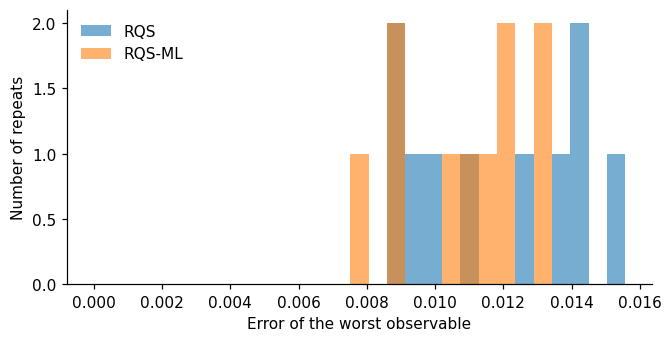

(Plan: 20,000 shots; test signal single_tone, ||A|| = 50.0 nT)


In [196]:
# ✏️ Number of simulated repeat experiments (more = more reliable statistics, slower).
N_TRIALS = 200 if N_NV == 1 else 10   # with N_NV > 1, each trial repeats the whole multi-NV experiment

if USE_SIMULATED_DATA:
    worst = {method: [] for method in results}
    for seed in range(1000, 1000 + N_TRIALS):
        if N_NV > 1:   # fresh noise for every NV
            estimates, _ = decode_nvs(saved_plan, N_NV, True, true_amplitudes=true_amplitudes,
                                        start_times_s=sim_start_times, visibility=NV_VISIBILITY, offset=NV_OFFSET,
                                        t2_s=NV_T2, observable_weights=observable_weights, seed=seed*N_NV, verbose=False)
        else:
            trial = R.simulate(saved_plan, true_amplitudes, seed=seed, **timing)
            estimates = {m: R.decode(saved_plan, trial, method=m, **observable_weights) for m in worst}
        for method in worst:
            worst[method].append(np.max(np.abs(np.asarray(estimates[method].values) - truth)))

    print(f"Error of the worst observable, over {N_TRIALS} simulated repeats of this experiment:")
    for method, errors in worst.items():
        typical, near_worst = np.quantile(errors, [0.5, 0.95])
        print(f"  {method:15s} typical {typical:.4f};  95% of repeats below {near_worst:.4f}")
    print(f"  (RQS bias with unlimited shots: {np.max(np.abs(np.asarray(noise_free.values) - truth)):.4f})")

    fig, ax = plt.subplots(figsize=(6, 3), constrained_layout=True)
    bins = np.linspace(0, max(max(e) for e in worst.values()), 30)
    for method, errors in worst.items():
        ax.hist(errors, bins=bins, alpha=.6, label=method)
    ax.set(xlabel="Error of the worst observable", ylabel="Number of repeats")
    ax.legend(frameon=False)
    plt.show()
    print(f"(Plan: {plan.total_shots:,} shots; test signal {TEST_SIGNAL}, "
          f"||A|| = {B_ref_t*1e9*np.linalg.norm(true_amplitudes):.1f} nT)")


In [36]:
# Check (simulation only): phase cycling cancels a readout offset the decoder doesn't know about.
SIM_OFFSET = 0.05
if USE_SIMULATED_DATA and saved_plan.field_mode == "phase_locked":
    p = saved_plan.pool
    phase = np.array([p.Z[r["sequence_index"]] @ true_amplitudes for r in saved_plan.rows])
    value = np.array([r["outcome_sign"]*np.sin(f) if r["basis"] == "Y" else np.cos(f)
                      for r, f in zip(saved_plan.rows, phase)])
    C = p.experiment.contrast(p.duration_s)
    m_plus, m_minus = SIM_OFFSET + C*value, SIM_OFFSET - C*value      # expected means, without shot noise
    print(f"Readout offset {SIM_OFFSET}, decoder told 0; errors vs truth in nT (no shot noise):")
    for label, means in (("one phase", m_plus), ("phase cycled", (m_plus - m_minus)/2)):
        A_hat = np.asarray(R.decode(saved_plan, R.AveragedOutcomes(list(means)), method="RQS").amplitudes)
        error = B_ref_t*1e9*(A_hat - true_amplitudes)
        print(f"  {label:13s} cos {np.round(error[:p.N], 1) + 0.}   sin {np.round(error[p.N:], 1) + 0.}")
else:
    print("Skipped: needs phase-locked simulated data from step 5.")

Readout offset 0.05, decoder told 0; errors vs truth in nT (no shot noise):
  one phase     cos [11.8 13.   6.4 16.4 14.2]   sin [ 0.4 -1.2 -5.8 -2.6 -2.1]
  phase cycled  cos [-1.8 -1.  -1.7  1.   0.1]   sin [ 1.   0.4 -0.9 -1.7 -1.1]


## Assumptions

- π pulses are ideal and instantaneous.
- The signal's frequencies and amplitudes stay fixed during the acquisition.
- Phase-locked mode needs every shot to start at the same signal phase; free-running mode
  needs accurate start times from one stable clock.
- No estimator gives a guaranteed error bar. Use step 8 with signals like yours to see
  what accuracy to expect.